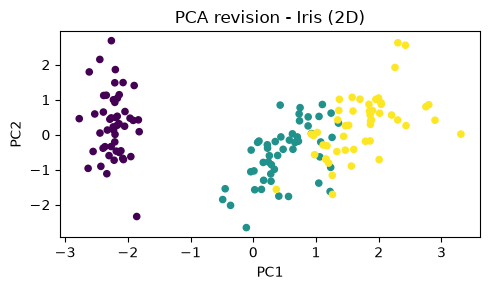

Explained variance ratio: [0.72962445 0.22850762]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- Quick revision snippet ---
iris = load_iris()
X_rev = StandardScaler().fit_transform(iris.data)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_rev)

plt.figure(figsize=(5, 3))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap='viridis', s=20)
plt.title("PCA revision - Iris (2D)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_)

# Viva notes:
# - PCA finds orthogonal directions (principal components) of maximum variance
# - n_components reduces dimensionality; first PC has highest variance
# - explained_variance_ratio_ shows fraction of info retained per component
# - Always standardize (mean=0, std=1) BEFORE PCA so no feature dominates
# - PCA is unsupervised; does not use class labels


### Q17
Write a Python program to apply Principal Component Analysis (PCA) on the Iris dataset and reduce its dimensionality to 2 dimensions. You should use sklearn's PCA implementation. After reducing the dimensions, visualize the transformed data in a 2D scatter plot, coloring the points based on their respective classes.

Dataset Description:
- The Iris dataset consists of 150 samples with 4 features.
- The target variable is categorical with three classes (Setosa, Versicolor, Virginica).

Instructions:
- Import the necessary libraries.
- Load the Iris dataset from sklearn.datasets.
- Separate the features and the target variable.
- Standardize the features (mean = 0, variance = 1).
- Apply PCA to reduce the dimensionality of the dataset to 2 dimensions.
- Visualize the transformed data in a 2D scatter plot, using different colors for each class.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
# Load Iris dataset
iris = load_iris()
X = iris.data          # features (150 x 4)
y = iris.target        # class labels (0, 1, 2)
class_names = iris.target_names
print("Dataset shape:", X.shape)
print("Classes:", class_names)


Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [4]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean after scaling (should be ~0):", X_scaled.mean(axis=0).round(4))


Mean after scaling (should be ~0): [-0. -0. -0. -0.]


In [5]:
# Apply PCA - reduce to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Shape after PCA:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(f"Total variance retained: {pca.explained_variance_ratio_.sum():.4f}")


Shape after PCA: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total variance retained: 0.9581


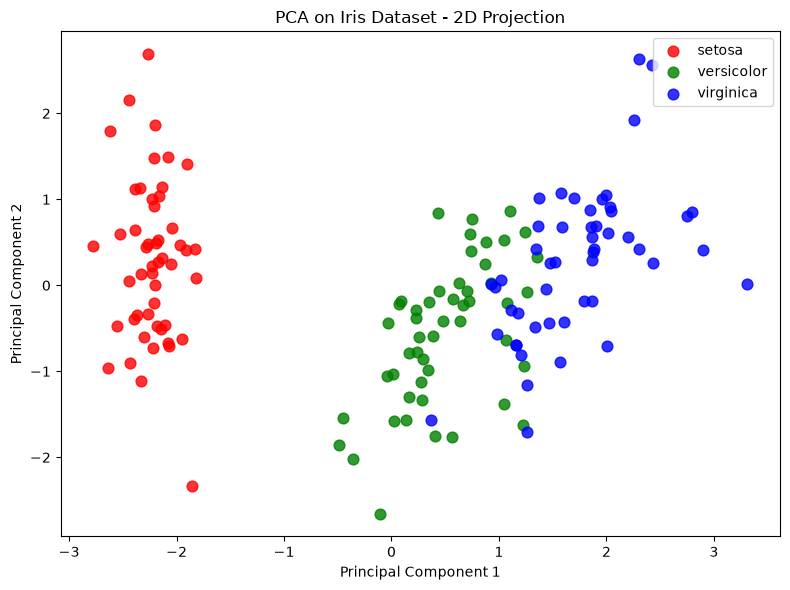

In [6]:
# 2D scatter plot colored by class
colors = ['red', 'green', 'blue']
plt.figure(figsize=(8, 6))

for i, (cls, col) in enumerate(zip(class_names, colors)):
    mask = y == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                color=col, label=cls, s=60, alpha=0.8)

plt.title("PCA on Iris Dataset - 2D Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()


### Q18
Apply Principal Component Analysis (PCA) to the Iris dataset to reduce its dimensionality from 4 to 2 dimensions. You will visualize the PCA-reduced dataset in a 2D scatter plot using Matplotlib.

Instructions:
- Load the Iris dataset.
- Briefly explore the dataset to understand its structure. Print the shape of the dataset and the first few rows.
- Initialize the PCA object to reduce the dataset to 2 dimensions.
- Fit the PCA model to the Iris dataset and transform the dataset.
- Use Matplotlib to create a scatter plot of the PCA-reduced dataset.
- Color the points based on their respective species (Setosa, Versicolor, Virginica).
- Add appropriate titles and labels to the axes.
- Include a legend to indicate which colors correspond to which species.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA


In [8]:
# Load and explore dataset
iris = load_iris()
X = iris.data
y = iris.target
class_names = iris.target_names

# Dataset exploration
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [class_names[i] for i in y]

print("Shape:", X.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nFeature names:", iris.feature_names)
print("Target names :", class_names)


Shape: (150, 4)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names : ['setosa' 'versicolor' 'virginica']


In [9]:
# Apply PCA (no standardization required per question instructions)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("PCA output shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)


PCA output shape: (150, 2)
Explained variance ratio: [0.92461872 0.05306648]


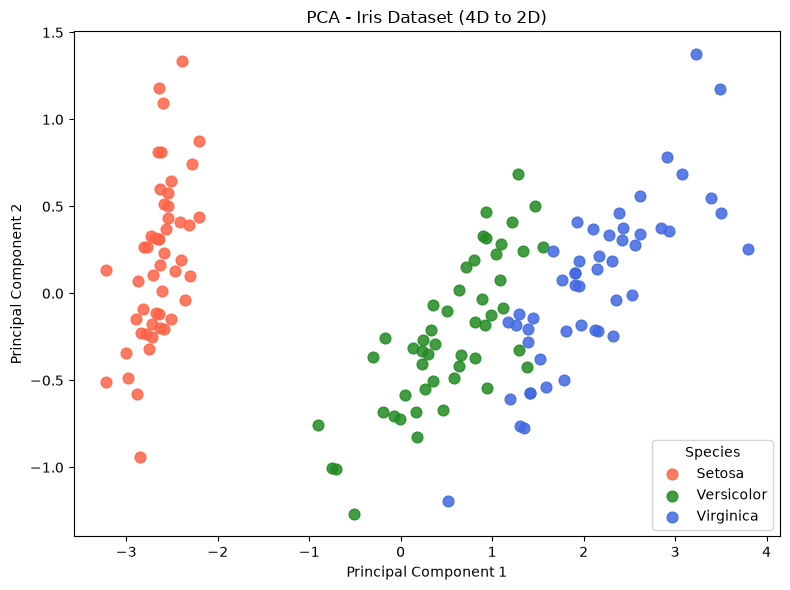

In [10]:
# Scatter plot with legend
colors = ['tomato', 'forestgreen', 'royalblue']
plt.figure(figsize=(8, 6))

for i, (cls, col) in enumerate(zip(class_names, colors)):
    mask = y == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                color=col, label=cls.capitalize(), s=60, alpha=0.85)

plt.title("PCA - Iris Dataset (4D to 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Species")
plt.tight_layout()
plt.show()


### Q19
Write a python snippet to demonstrate use of PCA on 100 samples with 3 features generated randomly.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


In [12]:
# Generate exactly 100 samples with 3 features
np.random.seed(42)
X = np.random.randn(100, 3)
print("Shape before PCA:", X.shape)


Shape before PCA: (100, 3)


In [13]:
# Apply PCA - reduce 3D to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Shape after PCA :", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(f"Total variance retained : {pca.explained_variance_ratio_.sum():.4f}")


Shape after PCA : (100, 2)
Explained variance ratio: [0.45375329 0.3221149 ]
Total variance retained : 0.7759


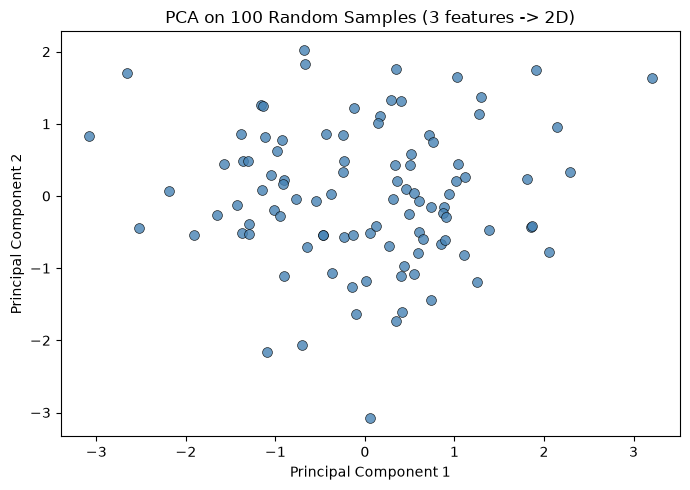

In [14]:
# Scatter plot of 2D result
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='steelblue', s=50, alpha=0.8, edgecolors='k', linewidths=0.5)
plt.title("PCA on 100 Random Samples (3 features -> 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


### Q20
Write a python snippet to demonstrate use of PCA on dataset of your choice. Also print explained variance of all principal components.


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [16]:
# Load Wine dataset (13 features - good for PCA demo)
wine = load_wine()
X = wine.data
y = wine.target
print("Wine dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes :", len(set(y)))


Wine dataset shape: (178, 13)
Number of features: 13
Number of classes : 3


In [17]:
# Standardize before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA keeping all components
pca = PCA()
pca.fit(X_scaled)

# Print explained variance for all components
print("Explained Variance Ratio per component:")
for i, evr in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {evr:.4f} ({evr*100:.2f}%)")

print(f"\nCumulative variance (first 2 PCs): {pca.explained_variance_ratio_[:2].sum():.4f}")
print(f"Cumulative variance (first 5 PCs): {pca.explained_variance_ratio_[:5].sum():.4f}")


Explained Variance Ratio per component:
  PC1: 0.3620 (36.20%)
  PC2: 0.1921 (19.21%)
  PC3: 0.1112 (11.12%)
  PC4: 0.0707 (7.07%)
  PC5: 0.0656 (6.56%)
  PC6: 0.0494 (4.94%)
  PC7: 0.0424 (4.24%)
  PC8: 0.0268 (2.68%)
  PC9: 0.0222 (2.22%)
  PC10: 0.0193 (1.93%)
  PC11: 0.0174 (1.74%)
  PC12: 0.0130 (1.30%)
  PC13: 0.0080 (0.80%)

Cumulative variance (first 2 PCs): 0.5541
Cumulative variance (first 5 PCs): 0.8016


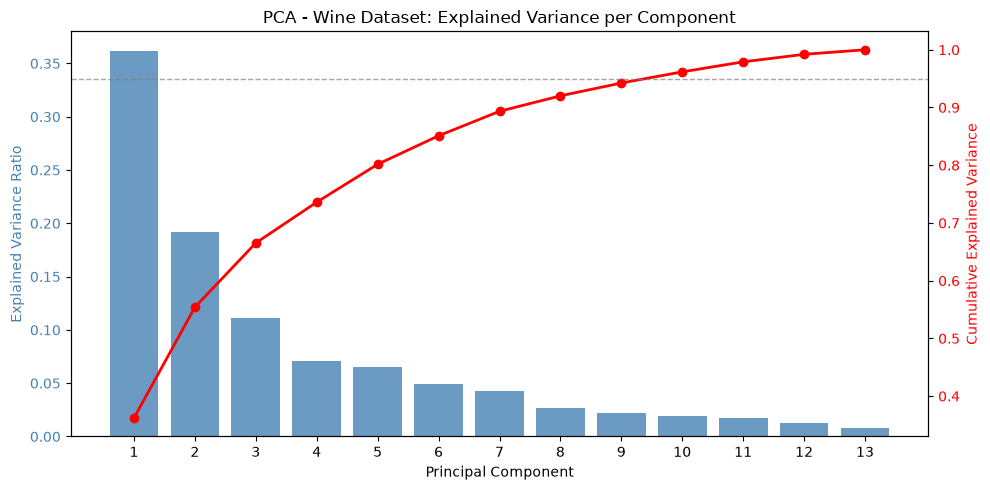

In [18]:
# Bar chart of explained variance + cumulative line
evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)
components = range(1, len(evr) + 1)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(components, evr, color='steelblue', alpha=0.8, label='Individual Variance')
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance Ratio", color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xticks(list(components))

ax2 = ax1.twinx()
ax2.plot(list(components), cum_evr, 'ro-', linewidth=2, label='Cumulative Variance')
ax2.set_ylabel("Cumulative Explained Variance", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.axhline(y=0.95, color='gray', linestyle='--', linewidth=1, alpha=0.7)

ax1.set_title("PCA - Wine Dataset: Explained Variance per Component")
fig.tight_layout()
plt.show()


### Q21
Use load_iris from sklearn.datasets to load the Iris dataset. Initialize the PCA object with n_components=2 to reduce the dataset to 2 dimensions. Use matplotlib to plot the PCA-reduced dataset in 2D.


In [19]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA


In [20]:
# Load Iris and apply PCA
iris = load_iris()
X = iris.data
y = iris.target

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Shape before PCA:", X.shape)
print("Shape after PCA :", X_pca.shape)


Shape before PCA: (150, 4)
Shape after PCA : (150, 2)


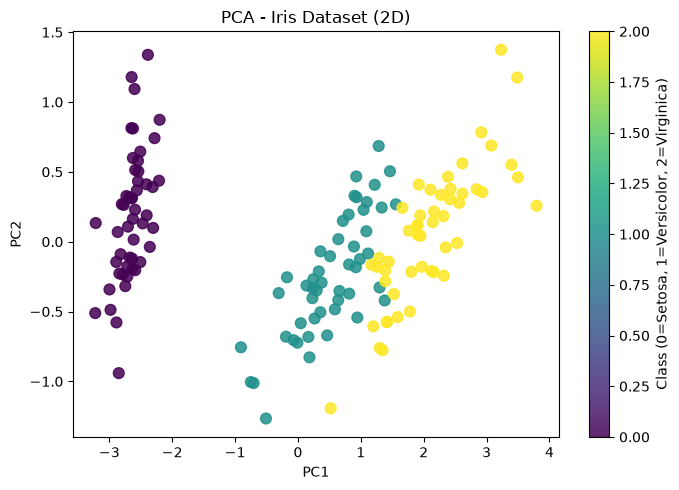

In [21]:
# 2D scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=60, alpha=0.85)
plt.colorbar(label='Class (0=Setosa, 1=Versicolor, 2=Virginica)')
plt.title("PCA - Iris Dataset (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()
